# How hot is the soil at the Moon's south pole?

**Reproducing ChaSTE's first result from Chandrayaan-3's public data.**

On 23 August 2023 Chandrayaan-3 landed at 69.4° S, the highest-latitude soft landing on the Moon. The next day the lander pushed **ChaSTE** (Chandra's Surface Thermophysical Experiment), a 10-sensor thermal probe, into the regolith. On 27 August ISRO released the first graph: about **70 °C at the surface**, falling to about **−10 °C at 80 mm** depth, a far steeper gradient than expected.

This notebook rebuilds that result from the archived data on ISRO's PRADAN portal, using the [`isda`](../README.md) readers:

1. Watch the probe go in (24 Aug), using its own penetration log.
2. Rebuild the temperature-vs-depth profile and compare it with ISRO's numbers.
3. Follow the profile through the lunar day.


In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*(plain CSV|label names missing).*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from isda import ch3

RAW = Path("../data/raw/ch3")  # unzipped PRADAN downloads; see the README
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

def days(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

def credit(fig, payload):
    fig.text(0.99, 0.005, f"Data: Chandrayaan-3 {payload}, ISRO / ISSDC PRADAN · © reserved ISRO",
             ha="right", va="bottom", fontsize=7, color="0.45")

## 1. Load the data

`ch3.chaste()` returns calibrated temperatures in kelvin, one column per sensor (1 = top of the probe), indexed by UTC. The insertion happened in the *commissioning* phase; the rest of the surface mission is *nominal operation*. The penetration log (motor stroke in mm) sits in the bundle's miscellaneous folder.

In [2]:
temps = pd.concat([ch3.chaste(RAW / "chaste", phase="commissioning"),
                   ch3.chaste(RAW / "chaste")]).sort_index()
celsius = temps - 273.15

log = RAW / "chaste/LTA_CHASTE/miscallaneous_data/operation phase/Penetration _stroke_current.txt"
stroke = pd.read_csv(log, sep=r"\s+")
stroke.columns = ["utc", "motor_ma", "stroke_mm"]
stroke = stroke.set_index(pd.to_datetime(stroke.pop("utc"), utc=True))

print(f"{len(temps):,} readings per sensor, {temps.index.min():%d %b %H:%M} to {temps.index.max():%d %b %H:%M} UTC")
print("Sensor depths when fully inserted (mm):", ch3.CHASTE_DEPTH_MM)

529,695 readings per sensor, 24 Aug 12:19 to 02 Sep 10:15 UTC
Sensor depths when fully inserted (mm): {1: 4, 2: 10, 3: 16, 4: 22, 5: 28, 6: 36, 7: 46, 8: 63, 9: 81, 10: 98}


## 2. The probe goes in

The probe is driven down in 2.65 mm steps by telecommand. Before insertion every sensor reads the same: the probe is sitting in sunlight on the lander. As each sensor enters the soil, it starts cooling toward the regolith's own temperature.

Insertion: 12:35 to 20:02 UTC on 24 Aug, 102 steps, 267.0 mm of stroke


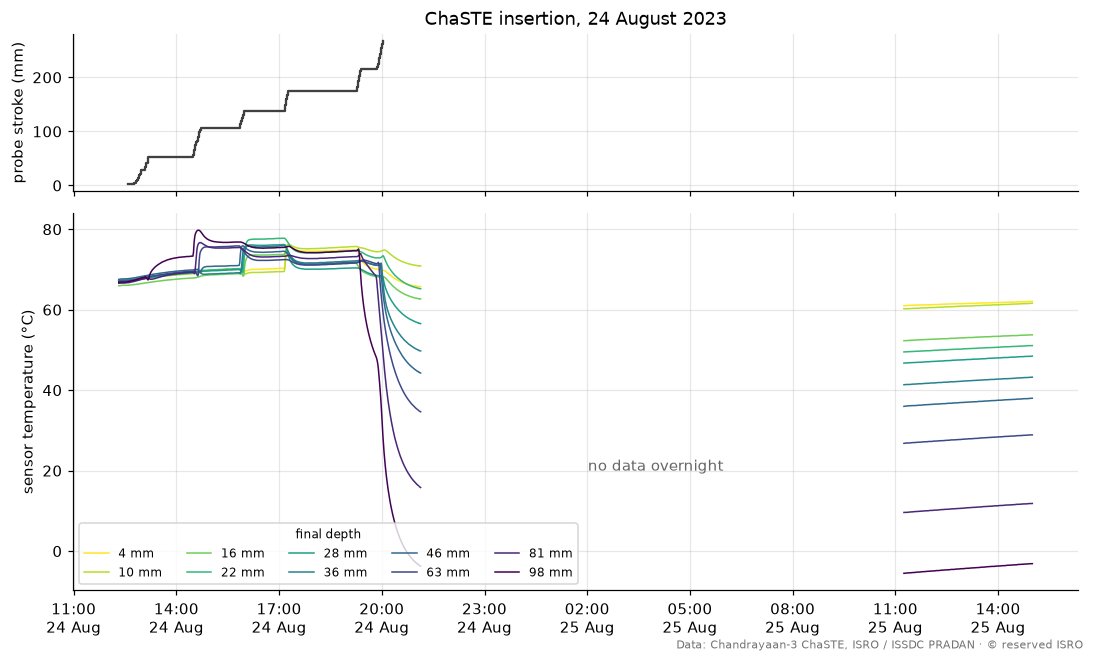

In [3]:
insertion = stroke.loc[:"2023-08-24 23:59"]
done = insertion.stroke_mm.idxmax()
print(f"Insertion: {insertion.index[0]:%H:%M} to {done:%H:%M} UTC on 24 Aug, "
      f"{len(insertion)} steps, {insertion.stroke_mm.max():.1f} mm of stroke")

window = celsius.loc["2023-08-24 12:00":"2023-08-25 15:00"].resample("1min").mean()  # gaps stay empty
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[1, 2.4])
a1.step(insertion.index, insertion.stroke_mm, where="post", color="0.25")
a1.set_ylabel("probe stroke (mm)")
a1.set_title("ChaSTE insertion, 24 August 2023")
cmap = plt.get_cmap("viridis_r")
for s in window.columns:
    a2.plot(window.index, window[s], lw=1, color=cmap((s - 1) / 9), label=f"{ch3.CHASTE_DEPTH_MM[s]} mm")
a2.set_ylabel("sensor temperature (°C)")
a2.legend(title="final depth", ncol=5, fontsize=8, title_fontsize=8, loc="lower left")
a2.xaxis.set_major_locator(mdates.HourLocator(interval=3))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d %b"))
a2.annotate("no data overnight", xy=(pd.Timestamp("2023-08-25 04:00", tz="UTC"), 20), ha="center", color="0.4")
credit(fig, "ChaSTE")
fig.tight_layout()

## 3. The temperature profile

Two snapshots after insertion: the first reading the next morning, once the probe had settled (closest to ISRO's 27 August graph), and the hottest moment in the soil. Readings from before insertion are left out: then the probe was sitting in sunlight on the lander, and every sensor read 67–80 °C. The hollow markers are the two numbers in ISRO's release.

,ISRO release (27 Aug 2023),this notebook
near-surface maximum,≈ 70 °C,"68.0 °C (4 mm, 28 Aug 11:25 UTC)"
coldest at depth,≈ −10 °C,"-5.6 °C (98 mm, 25 Aug 16:27 UTC)"


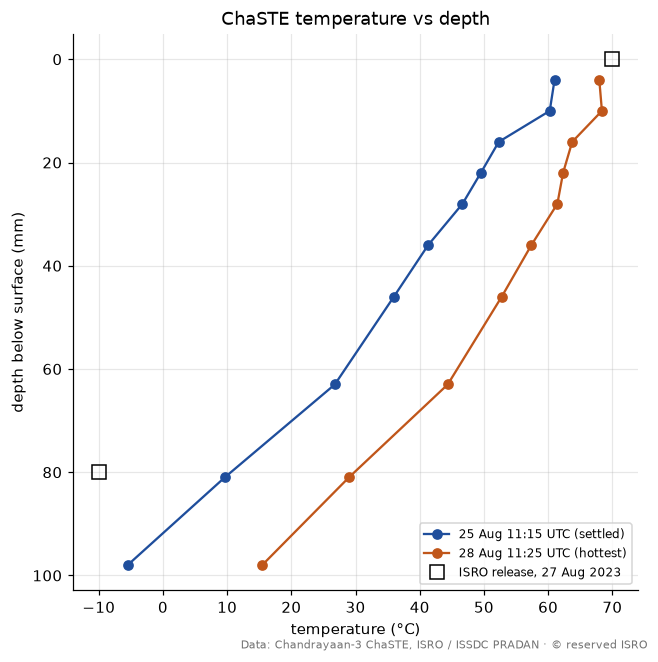

In [4]:
depth = pd.Series(ch3.CHASTE_DEPTH_MM)
in_soil = celsius.loc["2023-08-25 11:00":"2023-08-31 23:59"]  # after insertion, before the heater runs on 1-2 Sep
settled = in_soil.iloc[0]
peak_t = in_soil[1].idxmax()
snapshots = {f"{settled.name:%d %b %H:%M} UTC (settled)": settled,
             f"{peak_t:%d %b %H:%M} UTC (hottest)": celsius.loc[peak_t]}

fig, ax = plt.subplots(figsize=(6, 6))
for (label, row), c in zip(snapshots.items(), ["#1f4e9c", "#c0561a"]):
    ax.plot(row.values, depth.values, "o-", color=c, label=label)
ax.plot([70, -10], [0, 80], "s", mfc="none", mec="k", ms=9, label="ISRO release, 27 Aug 2023")
ax.invert_yaxis()
ax.set_xlabel("temperature (°C)")
ax.set_ylabel("depth below surface (mm)")
ax.set_title("ChaSTE temperature vs depth")
ax.legend(fontsize=8, loc="lower right")
credit(fig, "ChaSTE")
fig.tight_layout()

comparison = pd.DataFrame({
    "ISRO release (27 Aug 2023)": ["≈ 70 °C", "≈ −10 °C"],
    "this notebook": [f"{in_soil[1].max():.1f} °C (4 mm, {peak_t:%d %b %H:%M} UTC)",
                      f"{in_soil[10].min():.1f} °C (98 mm, {in_soil[10].idxmin():%d %b %H:%M} UTC)"],
}, index=["near-surface maximum", "coldest at depth"])
comparison

## 4. Through the lunar day

The Sun stays low at 69° S and moves slowly across the two-week lunar day. Hourly means for four depths. The bumps on 1–2 September are most likely ChaSTE's active heating experiments (a heater at sensor 9 is switched on to measure the soil's thermal conductivity), so the gradient is computed before them.

Gradient between 4 and 98 mm, 25-31 Aug: 3.9 to 6.8 °C per cm


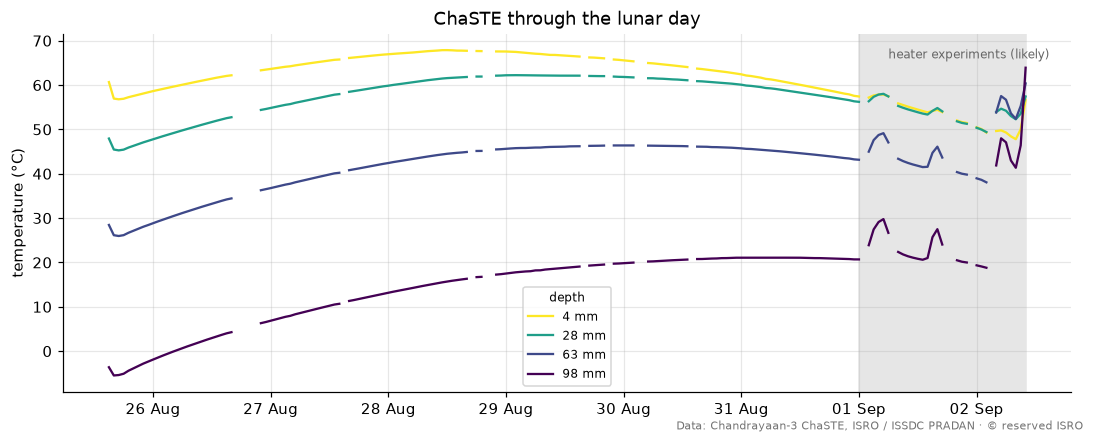

In [5]:
hourly = celsius.loc["2023-08-25 15:00":].resample("1h").mean()
fig, ax = plt.subplots(figsize=(10, 4))
for s in [1, 5, 8, 10]:
    ax.plot(hourly.index, hourly[s], color=cmap((s - 1) / 9), label=f"{ch3.CHASTE_DEPTH_MM[s]} mm")
ax.axvspan(pd.Timestamp("2023-09-01", tz="UTC"), hourly.index[-1], color="0.9", zorder=0)
ax.text(pd.Timestamp("2023-09-01 06:00", tz="UTC"), 66, "heater experiments (likely)", fontsize=8, color="0.4")
days(ax)
ax.set_ylabel("temperature (°C)")
ax.set_title("ChaSTE through the lunar day")
ax.legend(title="depth", fontsize=8, title_fontsize=8)
credit(fig, "ChaSTE")
fig.tight_layout()

quiet = hourly.loc[:"2023-08-31 23:59"]
gradient = (quiet[1] - quiet[10]) / (ch3.CHASTE_DEPTH_MM[10] - ch3.CHASTE_DEPTH_MM[1]) * 10
print(f"Gradient between 4 and 98 mm, 25-31 Aug: {gradient.min():.1f} to {gradient.max():.1f} °C per cm")

## What this reproduces, and what it doesn't

- **Reproduced:** the near-surface maximum. The 4 mm sensor peaks at about 68 °C, matching ISRO's "about 70 °C".
- **Reproduced:** a steep gradient, several °C per centimetre, in soil that conducts heat very poorly.
- **Not reproduced exactly:** ISRO's "−10 °C at 80 mm". In the released calibrated data the coldest reading is about −5 °C, at the 98 mm sensor; at 81 mm it's about +10 °C the morning after insertion. We haven't pinned down why; ISRO's plot may use a different depth reference or pre-calibration values.

**Caveats**
- Depths assume full insertion, with sensor 1 at 4 mm (ChaSTE user manual, Table 1). They don't apply while the probe was still going in.
- ISRO notes the values are what the sensors read; correcting for the probe's own heating is still being worked on.
- The later re-insertion site (the 59 °C flat spot in the 2025 paper) has only 8 minutes of calibrated data in the archive, so it isn't covered here.

---
**Acknowledgement.** We acknowledge the use of data from the Chandrayaan-3, of Indian Space Research Organisation (ISRO), available at the PRADAN Portal, Indian Space Science Data Centre (ISSDC). ChaSTE Payload is jointly developed by Space Physics Laboratory (SPL), Vikram Sarabhai Space Centre (VSSC), Thiruvananthapuram and Physical Research Laboratory (PRL), Ahmedabad. Figures carry "© reserved ISRO" as the data terms require.
